In [ ]:
# Stage 1: Dataset Inspection & Exploratory Verification

**Project Title**: Explainable Pneumonia Classification from Chest X-Ray Images Using Deep Learning  
**Academic Context**: MCA Semester Project  
**Target Task**: Binary Classification (`NORMAL` vs `PNEUMONIA`)  

---

### Objectives of this Notebook:
1. **Environment Verification**: Confirm TensorFlow and dependency versions.
2. **Directory Structure Verification**: Verify existence of `train`, `val`, and `test` splits and class subdirectories.
3. **Data Distribution Analysis**: Count samples per class and split, tabulate with pandas, and visualize with Matplotlib.
4. **Visual Inspection**: Display representative chest X-rays from both `NORMAL` and `PNEUMONIA` classes.
5. **Resolution & Mode Profiling**: Inspect spatial dimensions, aspect ratios, and color channel modes.
6. **Data Integrity Audit**: Safely verify image readability across the dataset without modifying any files.
7. **Validation Split Assessment**: Critically evaluate the default validation partition for modeling readiness.

> **Note**: This notebook is strictly exploratory. No models are trained, and no dataset files are modified or relocated.

## 1. Import Libraries & Verify Environment

We import standard scientific and data processing libraries (`pathlib`, `numpy`, `pandas`, `PIL`, `matplotlib`) along with `tensorflow` to confirm environment readiness.

In [1]:
import os
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

print(f"Python Version     : {sys.version.split()[0]}")
print(f"TensorFlow Version : {tf.__version__}")
print(f"NumPy Version      : {np.__version__}")
print(f"Pandas Version     : {pd.__version__}")
print(f"Pillow (PIL)       : {Image.__version__}")
print(f"GPU Available      : {bool(tf.config.list_physical_devices('GPU'))}")

Python Version     : 3.13.14
TensorFlow Version : 2.21.0
NumPy Version      : 2.5.3
Pandas Version     : 3.0.5
Pillow (PIL)       : 12.3.0
GPU Available      : False


## 2. Dataset Path Configuration & Directory Verification

The dataset path is specified **relative** to this notebook (`../dataset/chest_xray/`). We check for the presence of the primary split folders (`train`, `val`, `test`) and ensure both `NORMAL` and `PNEUMONIA` subdirectories exist within each split.

In [2]:
# Define relative path to the dataset directory
DATASET_PATH = Path("../dataset/chest_xray")
if not DATASET_PATH.exists():
    # Fallback for systems with capitalized 'Dataset' folder
    DATASET_PATH = Path("../Dataset/chest_xray")

print(f"Configured dataset path : {DATASET_PATH.resolve()}")
print(f"Directory exists        : {DATASET_PATH.exists()}\n")

SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]

# Verify split and class directory existence
dir_status = []
for split in SPLITS:
    split_dir = DATASET_PATH / split
    split_exists = split_dir.exists()
    for cls_name in CLASSES:
        cls_dir = split_dir / cls_name
        cls_exists = cls_dir.exists()
        dir_status.append({
            "Split": split,
            "Class": cls_name,
            "Path": str(cls_dir),
            "Directory Exists": cls_exists
        })

status_df = pd.DataFrame(dir_status)
status_df

Configured dataset path : E:\Pnuemonia Detection\Dataset\chest_xray
Directory exists        : True



,Split,Class,Path,Directory Exists
0,train,NORMAL,..\dataset\chest_xray\train\NORMAL,True
1,train,PNEUMONIA,..\dataset\chest_xray\train\PNEUMONIA,True
2,val,NORMAL,..\dataset\chest_xray\val\NORMAL,True
3,val,PNEUMONIA,..\dataset\chest_xray\val\PNEUMONIA,True
4,test,NORMAL,..\dataset\chest_xray\test\NORMAL,True
5,test,PNEUMONIA,..\dataset\chest_xray\test\PNEUMONIA,True


## 3. Image File Inventory & Count Summary

We inspect and count valid image files (`.jpeg`, `.jpg`, `.png`) across all splits and classes. The results are aggregated into a summary DataFrame containing counts, split totals, and class proportions.

In [3]:
SUPPORTED_EXTS = {".jpeg", ".jpg", ".png"}

inventory = []
file_dict = {split: {cls: [] for cls in CLASSES} for split in SPLITS}

for split in SPLITS:
    for cls_name in CLASSES:
        target_dir = DATASET_PATH / split / cls_name
        if target_dir.exists():
            images = [f for f in target_dir.iterdir() if f.is_file() and f.suffix.lower() in SUPPORTED_EXTS]
            file_dict[split][cls_name] = images
            inventory.append({
                "Split": split,
                "Class": cls_name,
                "Count": len(images)
            })
        else:
            inventory.append({
                "Split": split,
                "Class": cls_name,
                "Count": 0
            })

df_counts = pd.DataFrame(inventory)

# Calculate split totals and percentages
split_totals = df_counts.groupby("Split")["Count"].transform("sum")
df_counts["Split Total"] = split_totals
df_counts["Class Share (%)"] = (df_counts["Count"] / df_counts["Split Total"] * 100).round(2)

total_images = df_counts["Count"].sum()
print(f"\n>>> Total Image Inventory: {total_images} images <<<")
df_counts


>>> Total Image Inventory: 5856 images <<<


,Split,Class,Count,Split Total,Class Share (%)
0,train,NORMAL,1341,5216,25.71
1,train,PNEUMONIA,3875,5216,74.29
2,val,NORMAL,8,16,50.00
3,val,PNEUMONIA,8,16,50.00
4,test,NORMAL,234,624,37.50
5,test,PNEUMONIA,390,624,62.50


## 4. Class Distribution Visualization

We visualize the distribution of `NORMAL` vs `PNEUMONIA` across the training, validation, and testing partitions using side-by-side bar charts.

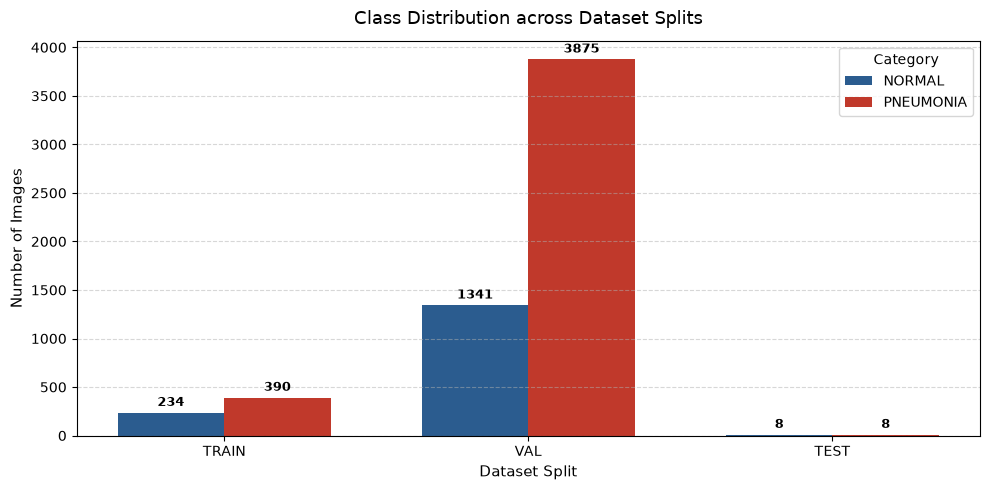

In [4]:
plt.figure(figsize=(10, 5), dpi=100)

pivot_df = df_counts.pivot(index="Split", columns="Class", values="Count")[CLASSES]
x = np.arange(len(SPLITS))
width = 0.35

plt.bar(x - width/2, pivot_df["NORMAL"], width, label="NORMAL", color="#2b5c8f")
plt.bar(x + width/2, pivot_df["PNEUMONIA"], width, label="PNEUMONIA", color="#c0392b")

# Annotate bars with counts
for idx in range(len(SPLITS)):
    norm_val = pivot_df["NORMAL"].iloc[idx]
    pneu_val = pivot_df["PNEUMONIA"].iloc[idx]
    plt.text(idx - width/2, norm_val + 40, str(norm_val), ha='center', va='bottom', fontsize=9, fontweight='bold')
    plt.text(idx + width/2, pneu_val + 40, str(pneu_val), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title("Class Distribution across Dataset Splits", fontsize=13, pad=12)
plt.xlabel("Dataset Split", fontsize=11)
plt.ylabel("Number of Images", fontsize=11)
plt.xticks(x, [s.upper() for s in SPLITS], fontsize=10)
plt.legend(title="Category", frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Critical Observations: Validation Set Size & Class Imbalance

Analyzing the distribution table and plot reveals two critical domain characteristics that directly impact model training:

### 1. Severe Validation Split Undersizing
- The default Kaggle validation set (`val/`) contains **only 16 images** (8 `NORMAL` and 8 `PNEUMONIA`).
- **Impact**: An evaluation sample of 16 images is far too small to yield statistically reliable validation loss or accuracy metrics during model checkpointing and early stopping. A single misclassified image swings validation accuracy by $6.25\%$.
- **Strategy for Next Stage**: Before training, the data loading pipeline should dynamically carve a robust validation split (e.g., $10\% - 15\%$ of the `train` set, yielding $\approx 500-780$ validation images) using `tf.keras.utils.image_dataset_from_directory(validation_split=0.15, subset="validation")` or stratified splitting in code **without altering the dataset files on disk**.

### 2. Significant Class Imbalance in Training Split
- The training set contains **$3,875$ Pneumonia cases ($74.3\%$)** versus **$1,341$ Normal cases ($25.7\%$)**.
- **Impact**: Unweighted training can lead the model to favor the majority class (`PNEUMONIA`), increasing false negatives for healthy scans or inflating overall accuracy while failing on precision/recall balance.
- **Strategy for Next Stage**: Calculate class weights via `sklearn.utils.class_weight.compute_class_weight` and pass them to `model.fit(class_weight=...)`, alongside targeted data augmentation and tracking metrics like **Recall**, **Precision**, **F1-score**, and **ROC-AUC** rather than accuracy alone.

## 6. Visual Inspection of Representative Chest Radiographs

We inspect representative sample images from each category (`NORMAL` and `PNEUMONIA`) from the training partition to observe standard radiographic characteristics:
- **NORMAL**: Clear lung fields, sharp diaphragm contours, visible pulmonary markings without dense opacities.
- **PNEUMONIA**: Infiltrates, cloudiness, patchy consolidation, or diffuse opacity across lung lobes.

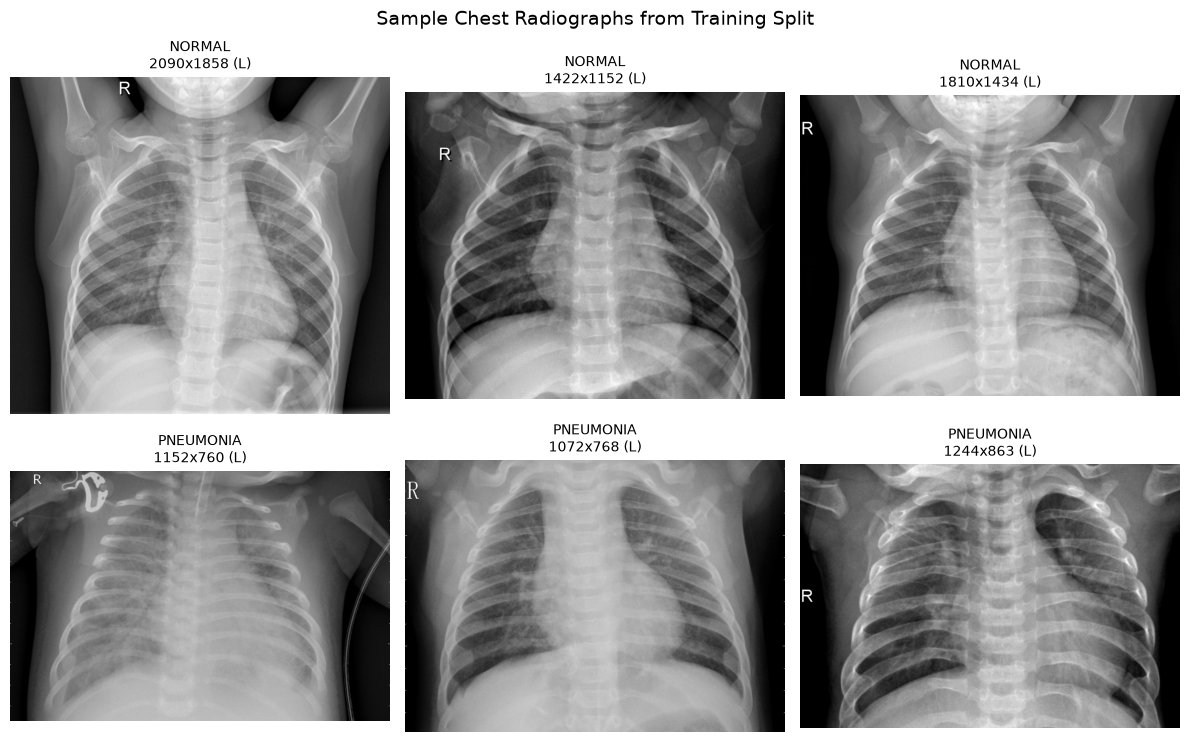

In [5]:
samples_per_class = 3
fig, axes = plt.subplots(len(CLASSES), samples_per_class, figsize=(12, 8))

for row_idx, cls_name in enumerate(CLASSES):
    img_paths = file_dict["train"][cls_name][:samples_per_class]
    for col_idx, img_path in enumerate(img_paths):
        ax = axes[row_idx, col_idx]
        try:
            with Image.open(img_path) as img:
                ax.imshow(img, cmap="gray")
                w, h = img.size
                ax.set_title(f"{cls_name}\n{w}x{h} ({img.mode})", fontsize=10)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error loading:\n{e}", ha="center", va="center")
        ax.axis("off")

plt.suptitle("Sample Chest Radiographs from Training Split", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

## 7. Inspection of Image Dimensions, Modes, and Aspect Ratios

Medical chest X-rays often vary substantially in physical acquisition resolution and color encoding (single-channel grayscale `L` vs 3-channel pseudo-RGB `RGB`).

We sample up to 500 images across the dataset to evaluate:
- Width and Height distributions (min, max, mean, median)
- Aspect ratio ($Width / Height$)
- Color modes (`L` vs `RGB`)

--- Image Mode Distribution ---
Mode
L      473
RGB     27
Name: count, dtype: int64

--- Dimension Summary Statistics (Pixels) ---


,Width,Height,Aspect Ratio
count,500.00,500.00,500.00
mean,1349.16,997.54,1.42
std,355.47,377.46,0.25
min,441.00,156.00,0.84
25%,1080.00,723.00,1.25
50%,1312.00,900.00,1.39
75%,1585.00,1215.75,1.56
max,2772.00,2628.00,3.15


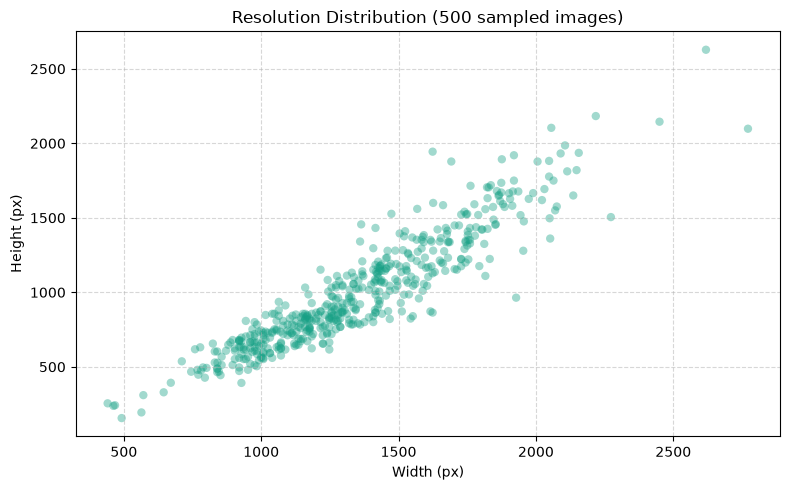

In [6]:
sample_records = []
sample_limit = 500

# Collect samples across train split
all_train_files = file_dict["train"]["NORMAL"] + file_dict["train"]["PNEUMONIA"]
np.random.seed(42)
sampled_files = np.random.choice(all_train_files, size=min(sample_limit, len(all_train_files)), replace=False)

for p in sampled_files:
    try:
        with Image.open(p) as img:
            w, h = img.size
            sample_records.append({
                "Width": w,
                "Height": h,
                "Aspect Ratio": round(w / h, 3),
                "Mode": img.mode,
                "Format": img.format
            })
    except Exception as e:
        pass

df_samples = pd.DataFrame(sample_records)

print("--- Image Mode Distribution ---")
print(df_samples["Mode"].value_counts())

print("\n--- Dimension Summary Statistics (Pixels) ---")
display(df_samples[["Width", "Height", "Aspect Ratio"]].describe().round(2))

# Plot dimension scatter
plt.figure(figsize=(8, 5), dpi=100)
plt.scatter(df_samples["Width"], df_samples["Height"], alpha=0.4, color="#16a085", edgecolors="none")
plt.title(f"Resolution Distribution ({len(df_samples)} sampled images)", fontsize=12)
plt.xlabel("Width (px)", fontsize=10)
plt.ylabel("Height (px)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Preprocessing Implications for Stage 2:
1. **Variable Resolutions**: Chest radiographs range from around $400 \times 600$ px up to over $2000 \times 2000$ px. Downsampling to a standardized input dimension (e.g., $224 \times 224$ px) will be necessary for CNN input tensors.
2. **Channel Format**: Some scans are stored as 1-channel grayscale (`L`) while others are 3-channel (`RGB`). The preprocessing pipeline must standardize all inputs into 3 channels (matching pretrained backbones like MobileNetV2 or ResNet50) or consistently convert to grayscale.

## 8. Data Integrity Audit (Safe Unreadable/Corrupt File Check)

We iterate through all images across all splits to test file readability using `PIL.Image.verify()`. No images are altered, renamed, moved, or deleted during this audit.

In [7]:
corrupt_files = []
total_checked = 0

for split in SPLITS:
    for cls_name in CLASSES:
        for img_path in file_dict[split][cls_name]:
            total_checked += 1
            try:
                with Image.open(img_path) as img:
                    img.verify()
            except Exception as e:
                corrupt_files.append((str(img_path), str(e)))

print(f"Integrity Audit Complete.")
print(f"Total Images Checked : {total_checked}")
print(f"Unreadable / Corrupt : {len(corrupt_files)}")

if corrupt_files:
    print("\nCorrupted files identified:")
    for path, err in corrupt_files:
        print(f" - {path}: {err}")
else:
    print("All inspected image files are valid and readable.")

Integrity Audit Complete.
Total Images Checked : 5856
Unreadable / Corrupt : 0
All inspected image files are valid and readable.
